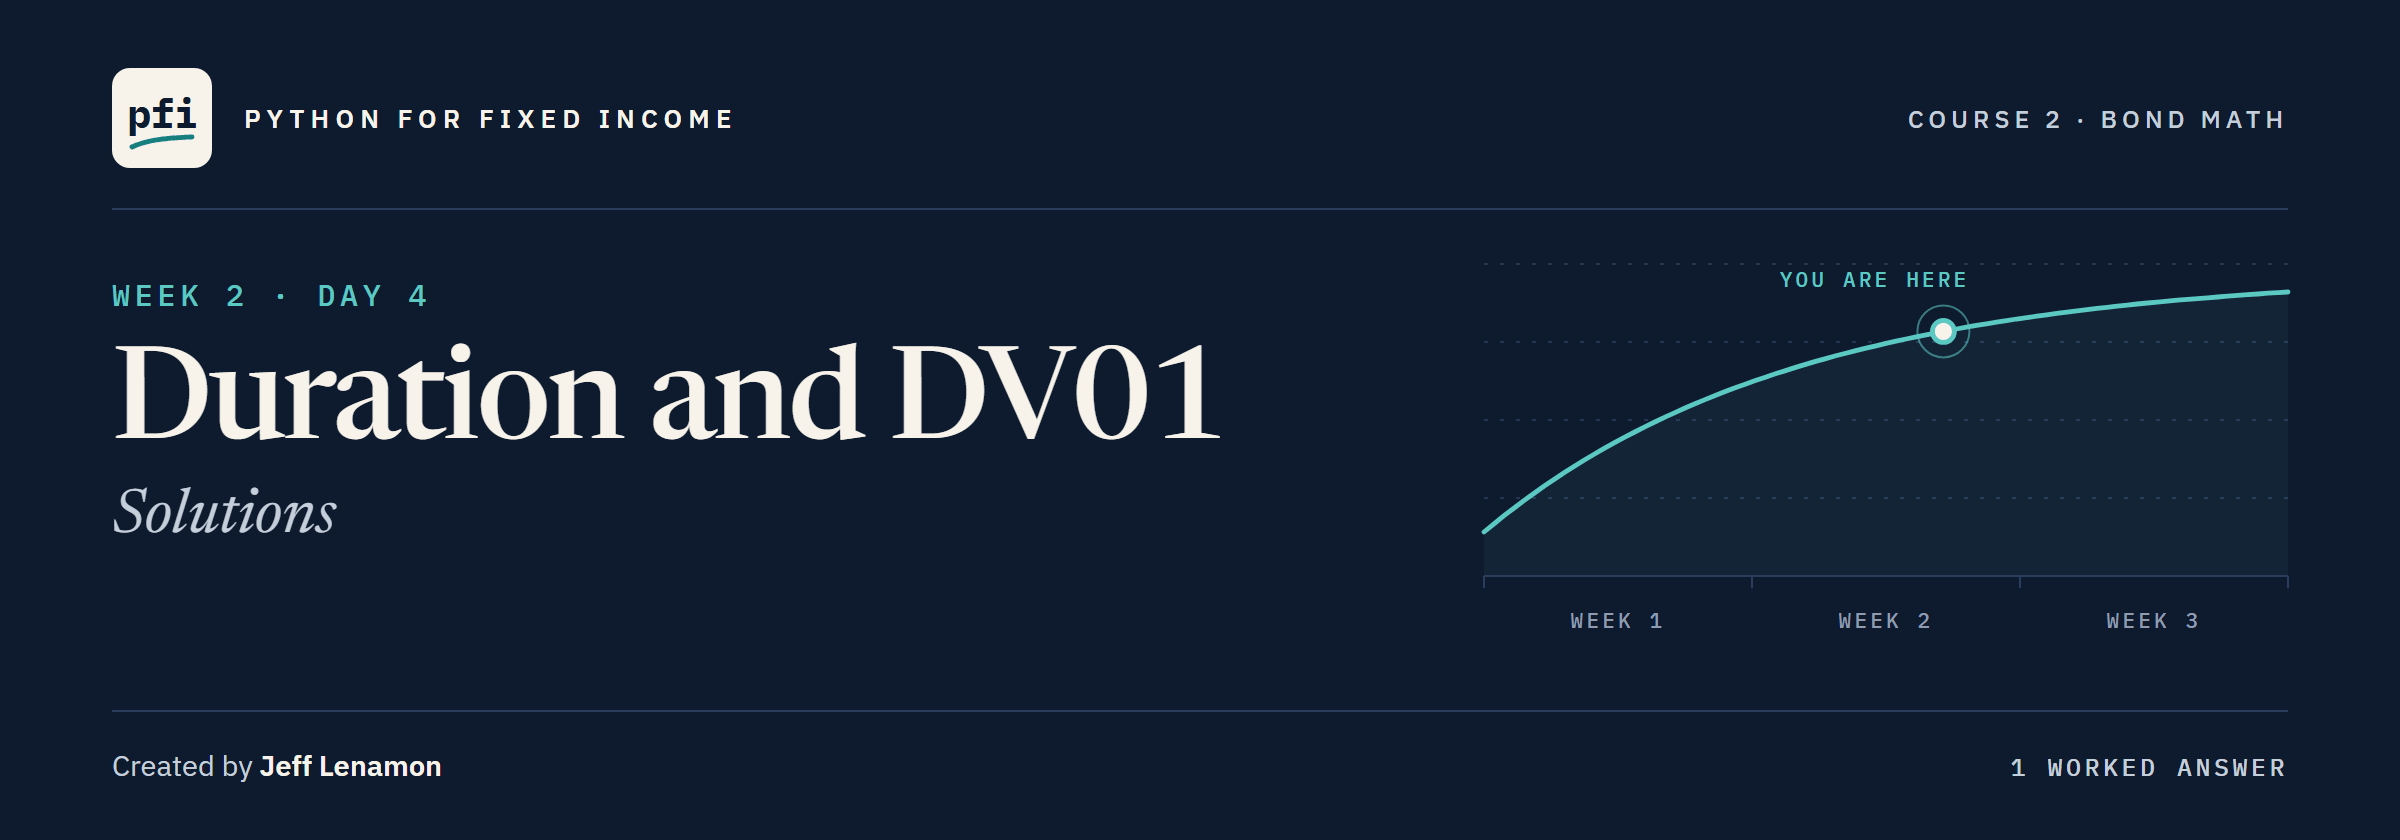

# Duration and DV01: Solutions

Week 2, Day 4. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week2/day4/09_duration_and_dv01_solutions.ipynb)

## Exercises

Run the next cells first: the work folder, with the module and tests as this notebook leaves them, the imports, `check`, and the bonds.

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/course02_bond_math/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}start_of_day/start_day.py
from start_day import start_day

# a new work folder: the Excel files, and the module and its tests as notebook 09 ends.
# To start the day again, restart the kernel and run all cells.
work = start_day(9, after=9)

Work folder pfi_course2_09_k4w7q2xr: 3 data files, the module as notebook 09 left it, 9 commits, tagged week1


In [2]:
import importlib
from datetime import date

import pandas as pd

import bondmath
settlement = date(2026, 11, 30)
reference = pd.read_csv('bondmath_excel_reference.csv')
print(len(reference), 'reference rows')

306 reference rows


In [3]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [4]:
exercise_bonds = pd.DataFrame({
    'ticker': ['OSTV', 'TRNW', 'OSMC', 'CLDB'],
    'coupon_pct': [5.625, 4.375, 5.0, 8.25],
    'maturity': [date(2030, 9, 30), date(2028, 9, 30), date(2032, 9, 30), date(2034, 9, 30)],
    'yield_pct': [5.8, 4.3, 5.35, 8.6],
    'par_held': [2_500_000, 6_000_000, 3_500_000, 1_500_000],
})
exercise_bonds

,ticker,coupon_pct,maturity,yield_pct,par_held
0,OSTV,5.625,2030-09-30,5.80,2500000
1,TRNW,4.375,2028-09-30,4.30,6000000
2,OSMC,5.000,2032-09-30,5.35,3500000
3,CLDB,8.250,2034-09-30,8.60,1500000


### Exercise 1

In [5]:
terms = list(zip(exercise_bonds['maturity'], exercise_bonds['coupon_pct'],
                 exercise_bonds['yield_pct']))
exercise_bonds['macaulay'] = [bondmath.macaulay_duration(settlement, m, c, y) for m, c, y in terms]
exercise_bonds['modified'] = [bondmath.modified_duration(settlement, m, c, y) for m, c, y in terms]
ex1_osmere_modified = exercise_bonds.set_index('ticker').loc['OSMC', 'modified']
# idxmax: the row label of the largest Macaulay duration
ex1_longest = exercise_bonds.loc[exercise_bonds['macaulay'].idxmax(), 'ticker']
exercise_bonds[['ticker', 'macaulay', 'modified']].round(6)

,ticker,macaulay,modified
0,OSTV,3.469260,3.371487
1,TRNW,1.770076,1.732821
2,OSMC,5.082342,4.949931
3,CLDB,5.821227,5.581234


In [6]:
check('Exercise 1 Osmere modified duration', ex1_osmere_modified, 4.949931473729879)
check('Exercise 1 longest Macaulay duration', ex1_longest, 'CLDB')

Exercise 1 Osmere modified duration: correct
Exercise 1 longest Macaulay duration: correct


Calderby, maturing in 2034, is the longest even with the highest coupon of the four.
In Excel: `=MDURATION(DATE(2026,11,30),DATE(2032,9,30),5/100,5.35/100,2,0)` returns Osmere's 4.949931473729879, its `week2` row.

### Exercise 2

In [7]:
tarnwick = exercise_bonds.set_index('ticker').loc['TRNW']
m, c, y = tarnwick['maturity'], tarnwick['coupon_pct'], tarnwick['yield_pct']
ex2_dv01 = bondmath.dv01(settlement, m, c, y)
# clean prices 1 bp either side, half the difference
ex2_bump = (bondmath.price(settlement, m, c, y - 0.01)
            - bondmath.price(settlement, m, c, y + 0.01)) / 2
print(f'Formula {ex2_dv01:.10f}, bump {ex2_bump:.10f} per 100')

Formula 0.0174763408, bump 0.0174763410 per 100


In [8]:
check('Exercise 2 Tarnwick DV01', ex2_dv01, 0.017476340807498596)
check('Exercise 2 Tarnwick bump', ex2_bump, 0.01747634098926909)

Exercise 2 Tarnwick DV01: correct
Exercise 2 Tarnwick bump: correct


Tarnwick's DV01 is small because it matures soonest, on 30 September 2028.

### Exercise 3

In [9]:
%%writefile -a bondmath.py


def position_dv01_dollars(par: float, dv01_per_100: float) -> float:
    """Position DV01 in dollars: what a position gains for a 1 basis point fall in yield.

    Units: par in dollars of face (negative for a short), dv01_per_100 in price points per 100 of
    face per bp; the result is in dollars per bp. Convention: dv01_per_100 x par / 100, so a long
    has a positive DV01 and a short a negative one.
    Excel: =dv01_cell*par/100
    """
    # price points per 100 of face, scaled to the face held
    return dv01_per_100 * par / 100

Appending to bondmath.py


In [10]:
%%writefile -a test_bondmath.py


def test_position_dv01_dollars_hand_case():
    # 1,000,000 of face at a DV01 of 0.05 per 100: 500 dollars per basis point
    assert bondmath.position_dv01_dollars(1_000_000, 0.05) == pytest.approx(500.0, abs=1e-9)
    # the same bond sold short: the sign turns
    assert bondmath.position_dv01_dollars(-1_000_000, 0.05) == pytest.approx(-500.0, abs=1e-9)
    # Quorvane, 5,000,000 of face, at Excel's DV01 from the reference file
    dv01_excel = float([row for row in REFERENCE if row["case_id"] == "99001BZA7"][0]["dv01"])
    expected = 5_000_000 * dv01_excel / 100
    assert bondmath.position_dv01_dollars(5_000_000, dv01_excel) == pytest.approx(expected, abs=1e-9)

Appending to test_bondmath.py


In [11]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

............................                                             [100%]
28 passed in 0.50s



In [12]:
# the file changed, so reload before calling the new function
importlib.reload(bondmath)
exercise_bonds['dv01'] = [bondmath.dv01(settlement, m, c, y) for m, c, y in terms]
exercise_bonds['position_dv01'] = [bondmath.position_dv01_dollars(par, d) for par, d
                                   in zip(exercise_bonds['par_held'], exercise_bonds['dv01'])]
ex3_book = exercise_bonds['position_dv01'].sum()
check('Exercise 3 book DV01 in dollars', ex3_book, 4443.097876532716)

Exercise 3 book DV01 in dollars: correct


In Excel, with the DV01 in B5: `=B5*6000000/100` gives Tarnwick's position DV01.

### Exercise 4: AI check

The bug: the assistant divides by (1 + y), the whole annual yield, where the docstring says (1 + y / frequency), the yield for one period.
On an annual bond the two are the same, so a test on annual rows alone would have missed it.
The fix divides by the frequency.

In [13]:
# written for this course in the style of an AI assistant's answer, now fixed
def assistant_modified_duration(settlement, maturity, coupon_pct, yield_pct, frequency=2,
                                basis='30/360'):
    """Modified duration in years: the percent price change for a 100 bp change in yield."""
    macaulay = bondmath.macaulay_duration(settlement, maturity, coupon_pct, yield_pct,
                                          frequency, basis)
    # the fix: one plus the yield for one period
    return macaulay / (1 + yield_pct / 100 / frequency)

In [14]:
# the test file's reference rows and bond_inputs (notebook 07), read as the tests read them
from test_bondmath import REFERENCE, bond_inputs
for row in REFERENCE:
    result = assistant_modified_duration(*bond_inputs(row))
    excel_value = float(row['mduration'])
    message = f"{row['case_id']}: {result:.6f}, MDURATION {excel_value:.6f}"
    assert abs(result - excel_value) < 1e-6, message
print("Every row matches Excel's MDURATION")

Every row matches Excel's MDURATION


In [15]:
ex4_quorvane = assistant_modified_duration(settlement, date(2031, 9, 30), 5.25, 5.40)
ex4_calderby = assistant_modified_duration(settlement, date(2034, 9, 30), 8.25, 8.60)
check('Exercise 4 Quorvane modified duration', ex4_quorvane, 4.180377687066381)
check('Exercise 4 Calderby modified duration', ex4_calderby, 5.581233589541736)

Exercise 4 Quorvane modified duration: correct
Exercise 4 Calderby modified duration: correct


[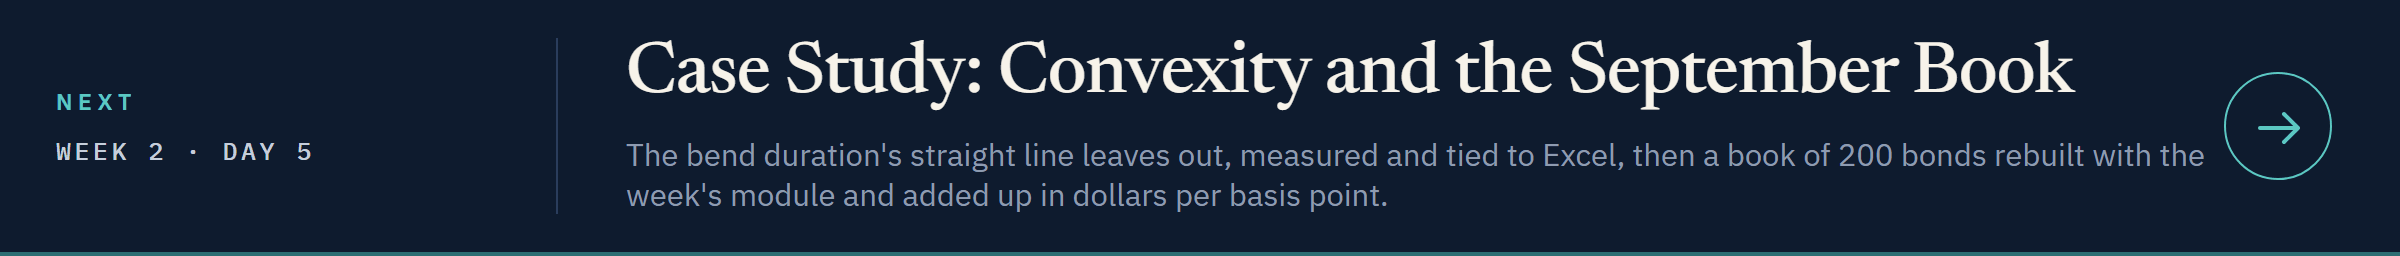](../day5/10_case_study_convexity_and_the_september_book.ipynb)

[Open Day 5 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week2/day5/10_case_study_convexity_and_the_september_book.ipynb)